In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("../data/raw/creditcard.csv")

# Display first five rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Exploratory Data Analysis

## 1. Dataset Overview

The objective of this analysis is to understand the structure,
quality, distributions, and relationships within the credit
card transaction dataset before developing machine learning models.

In [4]:
print("Number of transactions:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of transactions: 284807
Number of columns: 31

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [5]:
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values per column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Total missing values: 0


In [6]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

print(
    "Duplicate percentage:",
    round(duplicate_count / len(df) * 100, 4),
    "%"
)

Number of duplicate rows: 1081
Duplicate percentage: 0.3796 %


In [7]:
class_counts = df["Class"].value_counts().sort_index()

class_percentages = (
    df["Class"].value_counts(normalize=True).sort_index() * 100
)

print("Class distribution:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


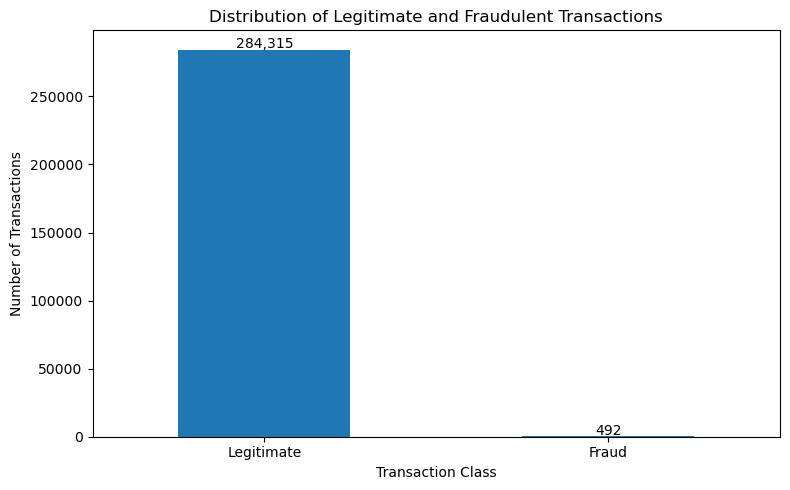

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

class_counts.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Distribution of Legitimate and Fraudulent Transactions")
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Number of Transactions")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Legitimate", "Fraud"], rotation=0)

for i, count in enumerate(class_counts):
    ax.text(
        i,
        count + 1000,
        f"{count:,}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [9]:
amount_stats = df.groupby("Class")["Amount"].describe()

print(amount_stats)

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


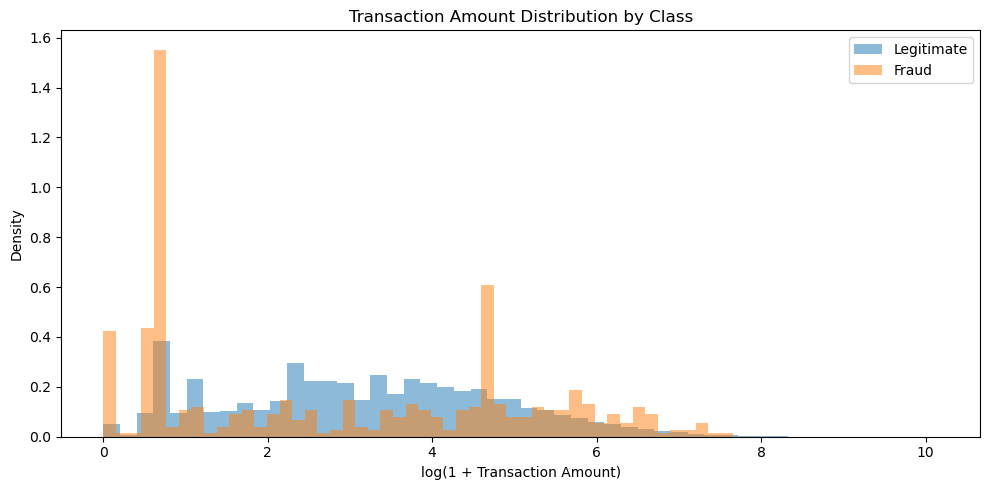

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))

for class_value, label in [(0, "Legitimate"), (1, "Fraud")]:
    amounts = np.log1p(
        df.loc[df["Class"] == class_value, "Amount"]
    )

    ax.hist(
        amounts,
        bins=50,
        alpha=0.5,
        density=True,
        label=label
    )

ax.set_title("Transaction Amount Distribution by Class")
ax.set_xlabel("log(1 + Transaction Amount)")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()

In [11]:
df["Elapsed_Hours"] = df["Time"] / 3600

df[["Time", "Elapsed_Hours"]].head()

,Time,Elapsed_Hours
0,0.0,0.000000
1,0.0,0.000000
2,1.0,0.000278
3,1.0,0.000278
4,2.0,0.000556


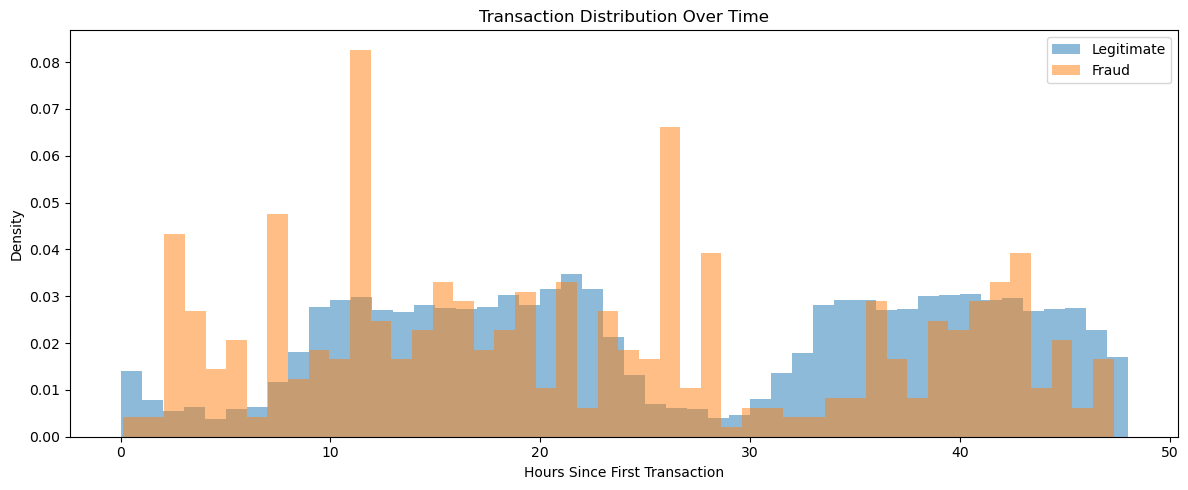

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))

for class_value, label in [(0, "Legitimate"), (1, "Fraud")]:
    subset = df[df["Class"] == class_value]

    ax.hist(
        subset["Elapsed_Hours"],
        bins=48,
        alpha=0.5,
        density=True,
        label=label
    )

ax.set_title("Transaction Distribution Over Time")
ax.set_xlabel("Hours Since First Transaction")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()

In [13]:
correlations = (
    df.drop(columns=["Elapsed_Hours"])
      .corr(numeric_only=True)["Class"]
      .drop("Class")
      .sort_values()
)

print(correlations)

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V6       -0.043643
Time     -0.012323
V24      -0.007221
V13      -0.004570
V15      -0.004223
V23      -0.002685
V22       0.000805
V25       0.003308
V26       0.004455
Amount    0.005632
V28       0.009536
V27       0.017580
V8        0.019875
V20       0.020090
V19       0.034783
V21       0.040413
V2        0.091289
V4        0.133447
V11       0.154876
Name: Class, dtype: float64


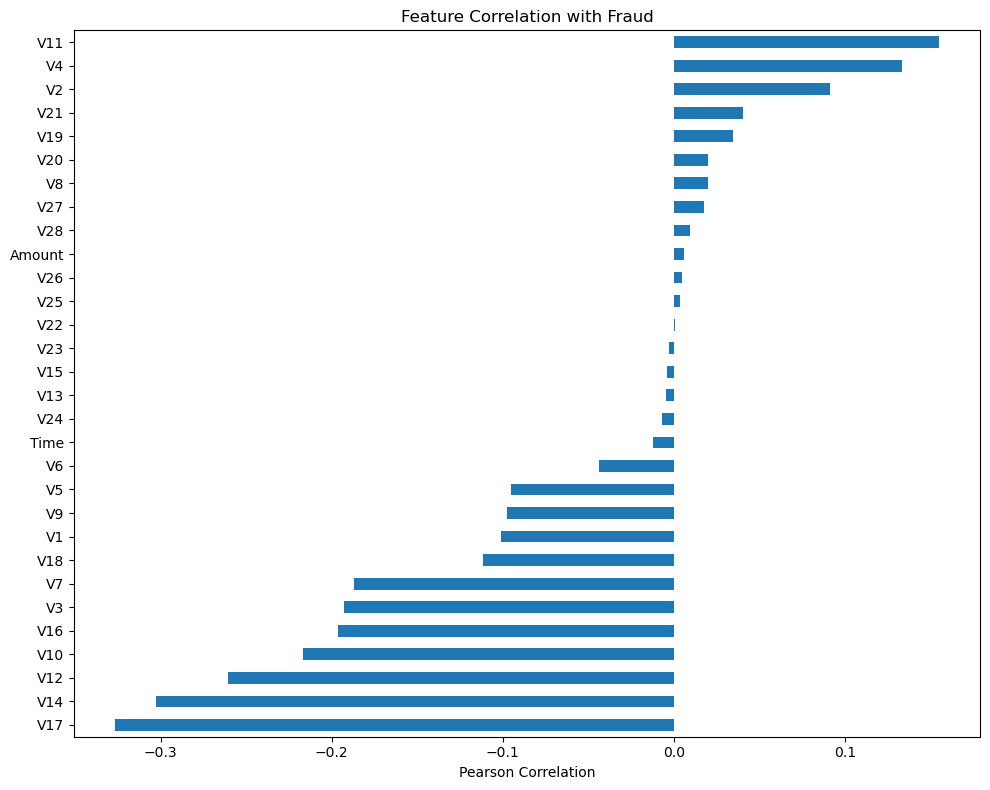

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))

correlations.plot(
    kind="barh",
    ax=ax
)

ax.set_title("Feature Correlation with Fraud")
ax.set_xlabel("Pearson Correlation")

plt.tight_layout()
plt.show()

In [15]:
Q1 = df["Amount"].quantile(0.25)
Q3 = df["Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Amount"] < lower_bound) |
    (df["Amount"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of amount outliers:", len(outliers))

print("\nOutliers by class:")
print(outliers["Class"].value_counts())

Lower bound: -101.7475
Upper bound: 184.5125
Number of amount outliers: 31904

Outliers by class:
Class
0    31813
1       91
Name: count, dtype: int64


# EDA Summary and Key Findings

## 1. Dataset Quality
- Missing values:
- Duplicate observations:
- Dataset dimensions:

## 2. Class Imbalance
- Legitimate transactions:
- Fraudulent transactions:
- Fraud percentage:

## 3. Transaction Amounts
- Main observations:
- Differences between classes:

## 4. Transaction Timing
- Main observations:
- Potential patterns:

## 5. Feature Relationships
- Features with strongest positive correlations:
- Features with strongest negative correlations:

## 6. Modeling Considerations
- Preserve the original class distribution in the test set.
- Avoid relying on accuracy alone.
- Investigate appropriate scaling and preprocessing.
- Prevent data leakage during preprocessing and resampling.
- Evaluate models using precision, recall, F1, and PR-AUC.